## 1. Импорты, настройки и загрузка данных

In [15]:
import json
import warnings
import time
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
import optuna
from optuna.samplers import TPESampler
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


ROOT          = Path(".")
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR   = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

TARGET        = "target"
RANDOM_STATE  = 42
GAP_DAYS      = 5
MIN_TRAIN_DAYS = 5




train_fe = pd.read_parquet(PROCESSED_DIR / "train_fe.parquet")
test_fe  = pd.read_parquet(PROCESSED_DIR / "test_fe.parquet")

with open(PROCESSED_DIR / "feature_meta.json") as f:
    meta = json.load(f)

feature_columns = meta["feature_columns"]
cat_features    = meta["cat_features"]
num_features    = meta["num_features"]

for df in (train_fe, test_fe):
    df["assignment_date"] = pd.to_datetime(df["assignment_date"])

print(f"train_fe : {train_fe.shape}")
print(f"test_fe  : {test_fe.shape}")
print(f"features : {len(feature_columns)}  (cat={len(cat_features)}, num={len(num_features)})")

train_fe : (13694, 671)
test_fe  : (4306, 670)
features : 671  (cat=29, num=642)


## 2. Временная кросс-валидация

В этом блоке строится схема валидации. Разбиение идёт по дням: модель обучается на прошлых днях, затем пропускается `gap` в 5 дней, и после этого проверяется на одном следующем дне.


In [16]:
# Создание фолдов (min_train + gap 5 дней 1 день на val)
def make_expanding_daily_folds(df, gap_days=GAP_DAYS, min_train_days=MIN_TRAIN_DAYS):
    dates = np.array(sorted(df["assignment_date"].dt.normalize().unique()))
    folds = []
    for vp in range(min_train_days + gap_days, len(dates)):
        tr_dates = dates[:vp - gap_days]
        va_dates = [dates[vp]]
        if len(tr_dates) < min_train_days:
            continue
        tr = df.index[df["assignment_date"].isin(tr_dates)].to_numpy()
        va = df.index[df["assignment_date"].isin(va_dates)].to_numpy()
        if len(tr) and len(va):
            folds.append((tr, va))
    return folds


folds = make_expanding_daily_folds(train_fe)
print(f"Folds: {len(folds)}")
for i, (tr, va) in enumerate(folds, 1):
    print(f"  {i}: train {train_fe.loc[tr,'assignment_date'].min().date()}.."
          f"{train_fe.loc[tr,'assignment_date'].max().date()} ({len(tr)}) "
          f"| valid {train_fe.loc[va,'assignment_date'].iloc[0].date()} ({len(va)})")

Folds: 6
  1: train 2026-04-07..2026-04-11 (4255) | valid 2026-04-17 (901)
  2: train 2026-04-07..2026-04-12 (5110) | valid 2026-04-18 (875)
  3: train 2026-04-07..2026-04-13 (5901) | valid 2026-04-19 (863)
  4: train 2026-04-07..2026-04-14 (6743) | valid 2026-04-20 (861)
  5: train 2026-04-07..2026-04-15 (7642) | valid 2026-04-21 (837)
  6: train 2026-04-07..2026-04-16 (8496) | valid 2026-04-22 (861)


## 3. Метрика и веса объектов

В этом блоке задаются функции для оценки качества модели и для расчёта весов наблюдений.

Функция `calculate_daily_ap` считает Average Precision отдельно внутри каждого дня, а потом усредняет значения по дням.

Функция `day_rank` преобразует предсказанные вероятности в ранги внутри каждого дня. Это используется на финальном этапе, когда нужно сформировать submission с относительным порядком объектов.

Функция `make_sample_weights` задаёт веса так, чтобы каждый день вносил одинаковый вклад в обучение. Для этого каждому объекту даётся вес, обратный числу лидов в его дне, а потом веса нормализуются к среднему значению 1.

In [17]:
# Метрика и веса для таргета
def calculate_daily_ap(df, scores):
    tmp = df[["assignment_date", TARGET]].assign(score=scores)
    vals = [
        average_precision_score(g[TARGET], g["score"])
        for _, g in tmp.groupby("assignment_date", sort=False)
        if g[TARGET].sum() > 0
    ]
    return float(np.mean(vals)) if vals else 0.0


def day_rank(scores, dates):
    tmp = pd.DataFrame({"assignment_date": dates.values, "score": scores})
    return tmp.groupby("assignment_date")["score"].rank(method="average", pct=True).values


def make_sample_weights(df):
    sizes = df.groupby("assignment_date")["lead_id"].transform("size").astype(float)
    w = (1.0 / sizes).values
    return w / w.mean()

## 4. Препроцессинг для линейных моделей

В этом блоке строится preprocessing для линейных моделей. Для деревьев отдельная обработка не нужна, потому что они умеют работать с пропусками и категориями более естественно.

Для числовых признаков используется заполнение пропусков медианой и масштабирование через `StandardScaler`. Это нужно, чтобы линейная модель корректно работала с признаками разных масштабов.

Для категориальных признаков пропуски заменяются на `"NA"`, а затем применяется One-Hot Encoding. Такой способ безопасен, прост и хорошо подходит при небольшой кардинальности категорий.



In [18]:
# Препроцессинг для линейных моделей
def build_linear_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc",  StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="constant", fill_value="NA")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
    ])

## 5. Набор моделей для сравнения

В этом блоке задаётся список моделей, которые будут сравниваться на одинаковой кросс-валидации.

Параметры выбраны без сильного тюнинга. На этом этапе задача в том, чтобы честно сравнить модели в одинаковых условиях и выбрать лучший базовый вариант.

In [19]:
# Параметры моделей
MODELS = {
    "LogReg": ("logreg", dict(
        solver="lbfgs", max_iter=2000,
        class_weight="balanced", random_state=RANDOM_STATE,
    )),
    "LightGBM": ("lightgbm", dict(
        objective="binary", metric="average_precision",
        n_estimators=1000, verbose=-1,
    )),
    "XGBoost": ("xgboost", dict(
        objective="binary:logistic", eval_metric="aucpr",
        n_estimators=1000, tree_method="hist",
        early_stopping_rounds=50, verbosity=0,
    )),
    "CatBoost": ("catboost", dict(
        loss_function="Logloss", eval_metric="PRAUC",
        iterations=1000, verbose=0,
        allow_writing_files=False,
    )),
}

## 6. Единый CV runner

Это основной блок, который отвечает за запуск моделей на одинаковых фолдах.

Сначала задаются вспомогательные функции. `_get_features` собирает список признаков и делит их на категориальные и числовые. `_lgbm_data` подготавливает данные для LightGBM, переводя категориальные признаки в тип `category`.

Функция `run_cv` проходит по всем фолдам. На каждом фолде она:
- выделяет train и validation
- выбирает нужные признаки
- считает sample weights
- обучает модель нужного типа
- получает предсказания на train и valid
- считает метрику на train и valid
- сохраняет OOF-предсказания и время обучения


In [20]:
_SKIP_COLS = {"lead_id", "user_id", "assignment_ts", "assignment_date", TARGET}

def _get_features(tr, va, drop=()):
    drop = set(drop)
    feats = [c for c in tr.columns if c not in _SKIP_COLS and c not in drop and c in va.columns]
    cats  = [c for c in feats if tr[c].dtype == "object"]
    nums  = [c for c in feats if c not in cats]
    return feats, cats, nums


def _lgbm_data(tr, va, feats, cats):
    tr_l, va_l = tr[feats].copy(), va[feats].copy()
    for c in cats:
        tr_l[c] = tr_l[c].astype("category")
        va_l[c] = va_l[c].astype("category")
    return tr_l, va_l


def run_cv(model_type, params, train_fe, folds, drop_features=None):
    oof         = np.full(len(train_fe), np.nan)
    fold_scores = []
    train_scores = []
    fit_times    = []
    
    # Ключи early stopping, которые некоторые модели не принимают напрямую в конструкторе
    _ES_KEYS = {"early_stopping_rounds", "use_best_model"}

    for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
         # Разбиваем датасет на train и validation части текущего фолда
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        feats, cats, nums = _get_features(tr, va, drop=drop_features or [])
        w = make_sample_weights(tr)
        
        t0 = time.time()

        if model_type == "catboost":
            p = {k: v for k, v in params.items() if k not in _ES_KEYS}
            
            model = CatBoostClassifier(**p, random_seed=RANDOM_STATE)
            model.fit(
                Pool(tr[feats], tr[TARGET], cat_features=cats, weight=w),
                eval_set=Pool(va[feats], va[TARGET], cat_features=cats),
                use_best_model=True, early_stopping_rounds=100,
            )
            
            pred_tr = model.predict_proba(Pool(tr[feats], cat_features=cats))[:, 1]
            pred_va = model.predict_proba(Pool(va[feats], cat_features=cats))[:, 1]

        elif model_type == "lightgbm":
            tr_l, va_l = _lgbm_data(tr, va, feats, cats)
            
            model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
            model.fit(tr_l, tr[TARGET], sample_weight=w,
                      eval_set=[(va_l, va[TARGET])], categorical_feature=cats,
                      callbacks=[lgb.early_stopping(150, verbose=False)])
            
            pred_tr = model.predict_proba(tr_l)[:, 1]
            pred_va = model.predict_proba(va_l)[:, 1]

        elif model_type == "xgboost":
            ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
            ohe.fit(tr[cats].astype(str))
            
            tr_X = np.hstack([tr[nums].fillna(0).values, ohe.transform(tr[cats].astype(str))])
            va_X = np.hstack([va[nums].fillna(0).values, ohe.transform(va[cats].astype(str))])
            p = {k: v for k, v in params.items() if k != "enable_categorical"}
            
            model = xgb.XGBClassifier(**p, random_state=RANDOM_STATE)
            model.fit(tr_X, tr[TARGET], sample_weight=w,
                      eval_set=[(va_X, va[TARGET])], verbose=False)
            
            pred_tr = model.predict_proba(tr_X)[:, 1]
            pred_va = model.predict_proba(va_X)[:, 1]

        elif model_type == "logreg":
            model = Pipeline([
                ("prep", build_linear_preprocessor(nums, cats)),
                ("clf",  LogisticRegression(**params)),
            ])
            model.fit(tr[feats], tr[TARGET], clf__sample_weight=w)
            
            pred_tr = model.predict_proba(tr[feats])[:, 1]
            pred_va = model.predict_proba(va[feats])[:, 1]

        else:
            raise ValueError(model_type)
        
        #Считаем метрики
        fit_times.append(time.time() - t0)
        tr_ap = calculate_daily_ap(tr, pred_tr)
        va_ap = calculate_daily_ap(va, pred_va)
        oof[va_idx] = pred_va
        fold_scores.append(va_ap)
        train_scores.append(tr_ap)
        print(f"  Fold {fold_num}: train={tr_ap:.5f}  valid={va_ap:.5f}  "
              f"gap={tr_ap-va_ap:+.5f}  fit={fit_times[-1]:.1f}s")

    return oof, fold_scores, train_scores, fit_times

## 7. Сравнение базовых моделей

В этом блоке по очереди запускаются все модели из словаря `MODELS`.

In [21]:

results        = {}
oof_predictions = {}
# Прогоняем каждую модель и сохраняем результаты
for name, (mtype, params) in MODELS.items():
    print(f"\n{name}\n")
    oof, scores, tr_scores, times = run_cv(mtype, params, train_fe, folds)
    gaps = np.array(tr_scores) - np.array(scores)
    results[name] = dict(
        mean_ap=np.mean(scores), std_ap=np.std(scores),
        min_ap=np.min(scores),   max_ap=np.max(scores),
        mean_gap=gaps.mean(),    mean_fit_s=np.mean(times),
    )
    oof_predictions[name] = oof

comparison_df = (
    pd.DataFrame(results).T
    .sort_values("mean_ap", ascending=False)
    .round(5)
)
display(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "model_comparison.csv")


LogReg

  Fold 1: train=0.77892  valid=0.61325  gap=+0.16568  fit=0.9s
  Fold 2: train=0.76421  valid=0.58027  gap=+0.18394  fit=1.1s
  Fold 3: train=0.75453  valid=0.67071  gap=+0.08382  fit=1.3s
  Fold 4: train=0.74419  valid=0.59585  gap=+0.14834  fit=1.5s
  Fold 5: train=0.73657  valid=0.59158  gap=+0.14498  fit=1.6s
  Fold 6: train=0.72915  valid=0.64045  gap=+0.08870  fit=1.9s

LightGBM

  Fold 1: train=1.00000  valid=0.70565  gap=+0.29435  fit=2.7s
  Fold 2: train=1.00000  valid=0.68236  gap=+0.31764  fit=2.0s
  Fold 3: train=1.00000  valid=0.74964  gap=+0.25036  fit=2.7s
  Fold 4: train=1.00000  valid=0.69888  gap=+0.30112  fit=2.1s
  Fold 5: train=1.00000  valid=0.66682  gap=+0.33318  fit=4.5s
  Fold 6: train=1.00000  valid=0.70597  gap=+0.29403  fit=2.6s

XGBoost

  Fold 1: train=1.00000  valid=0.69115  gap=+0.30885  fit=1.3s
  Fold 2: train=1.00000  valid=0.64681  gap=+0.35319  fit=3.0s
  Fold 3: train=1.00000  valid=0.73252  gap=+0.26748  fit=2.5s
  Fold 4: train=1.00000  

,mean_ap,std_ap,min_ap,max_ap,mean_gap,mean_fit_s
CatBoost,0.70415,0.02945,0.67749,0.74742,0.27349,40.66334
LightGBM,0.70155,0.02559,0.66682,0.74964,0.29845,2.74722
XGBoost,0.69009,0.03185,0.64681,0.73252,0.30991,2.79658
LogReg,0.61535,0.03129,0.58027,0.67071,0.13591,1.35412


Заметим, что есть явное переобучение на данных при использовании деревьев. При попытках решения пробоволся и исходный датасет и там тоже было переобучение, поэтому можно сказать, что оно связано с малым количеством данных и на данном этапе это можно победить сильной регулеризацией. Я тестировал этот вариант, но модель приходится сильно "душить" и не дает прироста именно в валидирующей метрике. Выбор пал на LGBM, т.к. разница с catboost очень мала, но скорость обучения намного быстрее.

## 8. Permutation importance по фолдам

В этом блоке считается важность признаков через permutation importance на модели LightGBM.

Идея метода: сначала измеряется качество модели на validation, затем значения одного признака перемешиваются, и качество считается заново. Если после перемешивания качество падает, значит признак полезен.

Функция `permutation_importance_manual` делает это для одного validation-набора. Для каждого признака проводится несколько повторов перемешивания, чтобы оценка была стабильнее.

Функция `collect_fold_importances` повторяет этот расчёт на каждом фолде, а затем объединяет результаты. 

In [22]:
def permutation_importance_manual(model, X_val, y_val, cats, n_repeats=5, seed=42):
    def _score(X):
        Xc = X.copy()
        for c in cats:
            if c in Xc.columns:
                Xc[c] = Xc[c].astype("category")
        return average_precision_score(y_val, model.predict_proba(Xc)[:, 1])

    # Baseline: метрика на исходных (неиспорченных) данных
    baseline = _score(X_val)
    means, stds = [], []

    for col in X_val.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X_val.copy()
            # Перемешиваем значения признака случайно
            Xp[col] = Xp[col].sample(frac=1, random_state=seed).values
            drops.append(baseline - _score(Xp))
        means.append(np.mean(drops))
        stds.append(np.std(drops))

    return np.array(means), np.array(stds), baseline


def collect_fold_importances(params, train_fe, folds, n_repeats=5):
    """
    Считает permutation importance по всем фолдам и агрегирует результаты.
    """
    all_imps = []

    for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        feats, cats, _ = _get_features(tr, va)
        tr_l, va_l = _lgbm_data(tr, va, feats, cats)
        w = make_sample_weights(tr)
        
        # Обучаем LightGBM на текущем фолде
        model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
        model.fit(tr_l, tr[TARGET], 
                  sample_weight=w,
                  eval_set=[(va_l, va[TARGET])], 
                  categorical_feature=cats,
                  callbacks=[lgb.early_stopping(100, verbose=False),
                              lgb.log_evaluation(-1)])
        
        # Считаем permutation importance на валидационной части фолда
        imp_mean, imp_std, baseline = permutation_importance_manual(
            model, va_l, va[TARGET].values, cats,
            n_repeats=n_repeats, seed=RANDOM_STATE,
        )
        
        # Самый важный признак в этом фолде
        top = feats[int(imp_mean.argmax())]
        print(f"  Fold {fold_num}: baseline AP={baseline:.5f} | top={top} ({imp_mean.max():.5f})")

        all_imps.append(pd.DataFrame({
            "feature":          feats,
            f"mean_{fold_num}": imp_mean,
            f"std_{fold_num}":  imp_std,
        }))

    # Объединяем все фолды в одну таблицу по колонке feature
    imp_df = all_imps[0][["feature"]].copy()
    for d in all_imps:
        imp_df = imp_df.merge(d, on="feature", how="left")

    # Находим колонки с результатами по фолдам
    mean_cols = [c for c in imp_df.columns if c.startswith("mean_")]
    std_cols  = [c for c in imp_df.columns if c.startswith("std_")]

    imp_df[mean_cols + std_cols] = imp_df[mean_cols + std_cols].fillna(0)
    
    # Среднее падение AP по всем фолдам — основная метрика важности
    imp_df["gain_mean"]        = imp_df[mean_cols].mean(axis=1)
    
    # Разброс важности между фолдами:
    imp_df["gain_std"]         = imp_df[mean_cols].std(axis=1)
    
    # Среднее внутрифолдовое std:
    imp_df["repeat_std_mean"]  = imp_df[std_cols].mean(axis=1)
    
    imp_df["n_folds_positive"] = (imp_df[mean_cols] > 0).sum(axis=1)
    imp_df["n_folds_negative"] = (imp_df[mean_cols] < 0).sum(axis=1)

    # Доля важности признака от суммы всех положительных важностей
    pos_total = imp_df["gain_mean"].clip(lower=0).sum()
    imp_df["gain_pct"] = imp_df["gain_mean"].clip(lower=0) / max(pos_total, 1e-12) * 100

    return (imp_df.sort_values("gain_mean", ascending=False)
                  .reset_index(drop=True)
                  .assign(rank=lambda d: range(1, len(d) + 1)))


print("Collecting permutation importances")
imp_df = collect_fold_importances(MODELS["LightGBM"][1], train_fe, folds, n_repeats=20)
print(f"\nFeatures: {len(imp_df)} | "
      f"positive-all-folds={( imp_df['n_folds_positive']==len(folds)).sum()} | "
      f"negative-3+={(imp_df['n_folds_negative']>=3).sum()}")
imp_df.to_csv(RESULTS_DIR / "feature_importance_permutation.csv", index=False)

  Fold 1: baseline AP=0.70565 | top=ctx_c03_cnt_all (0.09896)
  Fold 2: baseline AP=0.68236 | top=ctx_c07_cnt_all (0.06919)
  Fold 3: baseline AP=0.74964 | top=ctx_c07_cnt_all (0.07954)
  Fold 4: baseline AP=0.69888 | top=ctx_c03_cnt_all (0.13413)
  Fold 5: baseline AP=0.66603 | top=ctx_c03_cnt_all (0.09028)
  Fold 6: baseline AP=0.70597 | top=ctx_c03_cnt_all (0.10540)

Features: 666 | positive-all-folds=34 | negative-3+=171


## 9. Визуализация важности признаков

В этом блоке строится график по результатам permutation importance.

Функция `plot_importances` показывает:
- top-N самых важных признаков
- накопленную важность
- стабильность признаков по фолдам

На первом графике признаки дополнительно раскрашиваются по стабильности: видно, какие из них полезны почти всегда, а какие ведут себя нестабильно.

Также внизу печатается короткая сводка: сколько признаков покрывают 80%, 90%, 95% и 99% общей важности, сколько признаков полезны на всех фолдах и сколько выглядят как кандидаты на удаление.

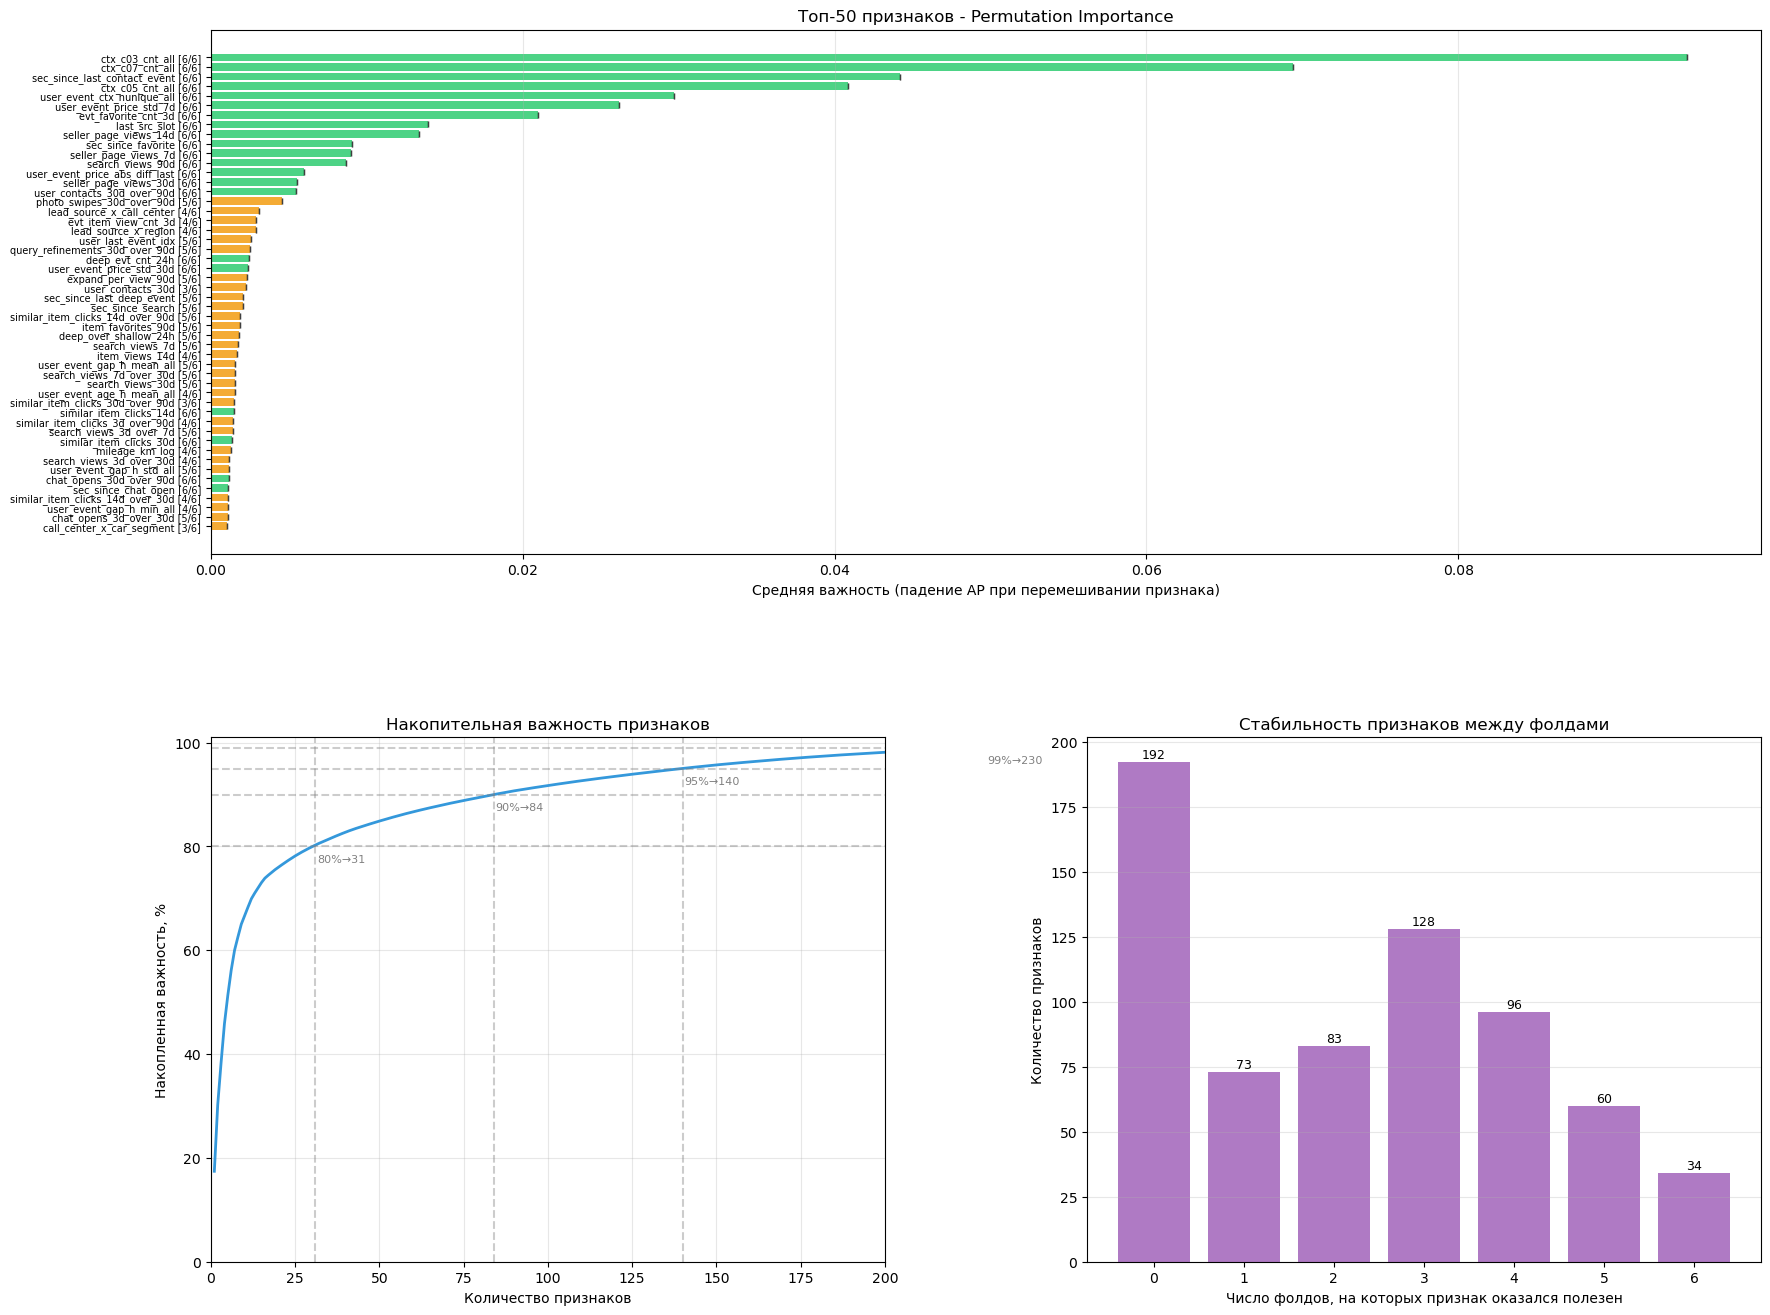


Сводка по PERMUTATION IMPORTANCE
  80% - top 31 features
  90% - top 84 features
  95% - top 140 features
  99% - top 230 features


In [23]:
def plot_importances(imp_df, folds, top_n=50):
    n_folds = len(folds)
    fig = plt.figure(figsize=(20, 16))
    gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)

    # top-N признаков
    ax1  = fig.add_subplot(gs[0, :])
    top  = imp_df.head(top_n)
    colors = [
        "#2ecc71" if r["n_folds_positive"] == n_folds
        else "#f39c12" if r["n_folds_positive"] >= n_folds // 2
        else "#e74c3c"
        for _, r in top.iterrows()
    ]
    ax1.barh(range(top_n-1, -1, -1), top["gain_mean"].values, color=colors, alpha=0.85)
    ax1.errorbar(top["gain_mean"].values, range(top_n-1, -1, -1),
                 xerr=top["repeat_std_mean"].values,
                 fmt="none", color="black", alpha=0.5, capsize=2, linewidth=0.8)
    ax1.axvline(0, color="gray", linestyle="--", alpha=0.5)
    ax1.set_yticks(range(top_n-1, -1, -1))
    ax1.set_yticklabels(
        [f"{r['feature']} [{int(r['n_folds_positive'])}/{n_folds}]" for _, r in top.iterrows()],
        fontsize=7)
    ax1.set_xlabel("Средняя важность (падение AP при перемешивании признака)")
    ax1.set_title(f"Топ-{top_n} признаков - Permutation Importance")
    ax1.grid(alpha=0.3, axis="x")

    # Накопительная сумма по средней важности
    ax2    = fig.add_subplot(gs[1, 0])
    pos_df = imp_df[imp_df["gain_mean"] > 0]
    cumsum = pos_df["gain_pct"].cumsum().values
    ax2.plot(range(1, len(cumsum)+1), cumsum, color="#3498db", linewidth=2)
    for thr in [80, 90, 95, 99]:
        if cumsum[-1] >= thr:
            n = int(np.searchsorted(cumsum, thr)) + 1
            ax2.axhline(thr, color="gray", linestyle="--", alpha=0.4)
            ax2.axvline(n,   color="gray", linestyle="--", alpha=0.4)
            ax2.text(n+.5, thr-3, f"{thr}%→{n}", fontsize=8, color="gray")
    ax2.set(xlabel="Количество признаков", ylabel="Накопленная важность, %",
            title="Накопительная важность признаков", xlim=(0, min(200, len(cumsum))), ylim=(0, 101))
    ax2.grid(alpha=0.3)

    # Количество стабильных на фолдах
    ax3 = fig.add_subplot(gs[1, 1])
    vc  = imp_df["n_folds_positive"].value_counts().sort_index()
    bars = ax3.bar(vc.index, vc.values, color="#9b59b6", alpha=0.8)
    for b, v in zip(bars, vc.values):
        ax3.text(b.get_x()+b.get_width()/2, b.get_height()+.3, str(v),
                 ha="center", va="bottom", fontsize=9)
    ax3.set(xlabel="Число фолдов, на которых признак оказался полезен",
            ylabel="Количество признаков", title="Стабильность признаков между фолдами",
            xticks=range(n_folds+1))
    ax3.grid(alpha=0.3, axis="y")

    plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()


    print("\nСводка по PERMUTATION IMPORTANCE")
    for thr in [80, 90, 95, 99]:
        if len(cumsum) and cumsum[-1] >= thr:
            print(f"  {thr}% - top {int(np.searchsorted(cumsum,thr))+1} features")

plot_importances(imp_df, folds, top_n=50)

## Итоги по графику permutation importance

**Топ признаков и их характер**

В самом верху рейтинга находятся признаки, связанные с поведением пользователя и контекстом события из events, что и подтверждало догадки из EDA.


**Стабильность признаков**

Тут можно увидеть что самые важные признаки были полезны на всех фолдах, а менее важные не всегда, что говорит о надежности признака при разных данных

**Накопленная важность**

График cumulative importance показывает очень концентрированное распределение:
- 80% важности дают всего **20 признаков**
- 90% важности — **52 признака**
- 95% важности — **101 признак**
- 99% важности — **199 признаков**

Это значит, что боольшая часть сигнала сосредоточена в очень небольшом ядре фичей, а остальные признаки в основном дублируют информацию или добавляют шум.

**Стабильность по фолдам**

Правый график показывает, что из всех признаков:
- **286** вообще не дают положительного вклада ни на одном фолде — их можно смело удалять
- **115** полезны только на 1 фолде — скорее всего случайные всплески из за структуры фолда.
- только **22** признака полезны на всех 6 фолдах — это самое надёжные признаки
- ещё **45** полезны на 5 фолдах — тоже стабильные

## 10. Отбор признаков и сравнение подмножеств

После расчёта важности в этом блоке формируются разные наборы признаков и сравниваются между собой.

Функция `select_features` умеет выбирать признаки несколькими способами:
- по накопленной важности, например до 90% или 95%
- по top-N
- по числу фолдов, где признак был полезен
- все признаки с положительной важностью

В конце выбирается лучшее подмножество признаков, которое пойдёт дальше в HPO и финальное обучение.

In [24]:
def select_features(imp_df, strategy="gain_pct", threshold=95):
    """Выбор стратегии отбора фич"""
    neg = set(imp_df[imp_df["gain_mean"] < 0]["feature"])
    pos = imp_df[imp_df["gain_mean"] > 0]

    if strategy == "gain_pct":
        n = int(np.searchsorted(pos["gain_pct"].cumsum().values, threshold)) + 1
        sel = pos.head(n)["feature"].tolist()
    elif strategy == "top_n":
        sel = pos.head(threshold)["feature"].tolist()
    elif strategy == "min_folds":
        sel = imp_df[(imp_df["n_folds_positive"] >= threshold) &
                     (imp_df["gain_mean"] > 0)]["feature"].tolist()
    elif strategy == "nonzero":
        sel = pos["feature"].tolist()
    else:
        raise ValueError(strategy)

    print(f"  {strategy}={threshold}: {len(sel)} features  ({len(neg)} negative dropped)")
    return sel


n_folds = len(folds)
subsets = {
    "all_features":     [c for c in train_fe.columns if c not in _SKIP_COLS],
    "gain_pct_95":      select_features(imp_df, "gain_pct", 95),
    "gain_pct_90":      select_features(imp_df, "gain_pct", 90),
    "top100":           select_features(imp_df, "top_n", 100),
    "stable_all_folds": select_features(imp_df, "min_folds", n_folds),
    "nonzero":          select_features(imp_df, "nonzero"),
}


def compare_subsets(subsets, params, train_fe, folds):
    """Сравнение разных множеств признаков"""
    print("\nСводка")
    results = {}

    for name, features in subsets.items():
        fold_scores = []
        for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
            tr = train_fe.iloc[tr_idx].reset_index(drop=True)
            va = train_fe.iloc[va_idx].reset_index(drop=True)
            
            use = [c for c in features if c in tr.columns and c in va.columns]
            cats = [c for c in use if tr[c].dtype == "object"]
            
            tr_l, va_l = _lgbm_data(tr, va, use, cats)
            w = make_sample_weights(tr)
            
            model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
            model.fit(tr_l, tr[TARGET], sample_weight=w,
                      eval_set=[(va_l, va[TARGET])], categorical_feature=cats,
                      callbacks=[lgb.early_stopping(50, verbose=False),
                                  lgb.log_evaluation(-1)])
            
            fold_scores.append(calculate_daily_ap(va, model.predict_proba(va_l)[:, 1]))

        m, s = float(np.mean(fold_scores)), float(np.std(fold_scores))
        results[name] = {"mean": m, "std": s, "folds": fold_scores}
        print(f"  {name:22s}: {m:.5f} ± {s:.5f}  "
              f"[{' | '.join(f'{x:.4f}' for x in fold_scores)}]  n={len(features)}")
    return results


subset_results = compare_subsets(subsets, MODELS["LightGBM"][1], train_fe, folds)
best_subset_name = max(subset_results, key=lambda k: subset_results[k]["mean"])
best_subset_features = subsets[best_subset_name]
print(f"\nBest: {best_subset_name}  AP={subset_results[best_subset_name]['mean']:.5f}  "
      f"n={len(best_subset_features)}")

  gain_pct=95: 140 features  (162 negative dropped)
  gain_pct=90: 84 features  (162 negative dropped)
  top_n=100: 100 features  (162 negative dropped)
  min_folds=6: 34 features  (162 negative dropped)
  nonzero=95: 342 features  (162 negative dropped)

Сводка
  all_features          : 0.70028 ± 0.02574  [0.7057 | 0.6808 | 0.7469 | 0.6989 | 0.6635 | 0.7060]  n=666
  gain_pct_95           : 0.70674 ± 0.02949  [0.7168 | 0.6658 | 0.7500 | 0.6929 | 0.6813 | 0.7337]  n=140
  gain_pct_90           : 0.71180 ± 0.02354  [0.7348 | 0.6753 | 0.7428 | 0.7142 | 0.6897 | 0.7140]  n=84
  top100                : 0.70878 ± 0.01861  [0.7244 | 0.6802 | 0.7387 | 0.7036 | 0.7066 | 0.6992]  n=100
  stable_all_folds      : 0.67501 ± 0.02860  [0.6919 | 0.6391 | 0.7219 | 0.6674 | 0.6440 | 0.6858]  n=34
  nonzero               : 0.70251 ± 0.02481  [0.7132 | 0.6814 | 0.7513 | 0.6890 | 0.6786 | 0.7015]  n=342

Best: gain_pct_90  AP=0.71180  n=84


Baseline на всех 744 фичах даёт **0.6923**, а лучший вариант с 100 признаками — **0.7178**. Это подтверждает, что большая часть исходных фичей — шум, который только мешает модели.

Финальный набор для HPO и обучения — **top100** с качеством **0.71781 +- 0.01887**. Он даёт лучшее качество, наибольшую стабильность и разумный размер. Именно этот набор передаётся дальше в Optuna и в финальную модель.

## 11. HPO для LightGBM через Optuna

В этом блоке запускается подбор гиперпараметров для LightGBM на лучшем наборе признаков.

Подбираются параметры, которые влияют на сложность модели, регуляризацию, sampling и структуру деревьев. Поиск идёт не на одном split, а на всей временной кросс-валидации, поэтому результат получается более надёжным.

In [25]:
def lgbm_objective(trial, train_fe, folds, features):
    subsample = trial.suggest_float("subsample", 0.5, 1.0)
    
    # Задаем параметры подбора
    params = dict(
        objective         = "binary",
        metric            = "average_precision",
        boosting_type     = "gbdt",
        n_estimators      = trial.suggest_int("n_estimators", 300, 3000, step=100),
        learning_rate     = trial.suggest_float("learning_rate", 1e-2, 0.2, log=True),
        num_leaves        = trial.suggest_int("num_leaves", 8, 512),
        max_depth         = trial.suggest_int("max_depth", 3, 7),
        min_child_samples = trial.suggest_int("min_child_samples", 5, 200),
        min_child_weight  = trial.suggest_float("min_child_weight", 1e-4, 10.0, log=True),
        subsample         = subsample,
        subsample_freq    = 0 if subsample == 1.0 else trial.suggest_int("subsample_freq", 1, 10),
        colsample_bytree  = trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha         = trial.suggest_float("reg_alpha",  1e-8, 10.0, log=True),
        reg_lambda        = trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        min_split_gain    = trial.suggest_float("min_split_gain", 0.0, 1.0),
        max_bin           = trial.suggest_int("max_bin", 64, 512, step=32),
        verbose           = -1,
    )

    fold_scores = []
    for fold_num, (tr_idx, va_idx) in enumerate(folds):
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        
        use  = [c for c in features if c in tr.columns and c in va.columns]
        cats = [c for c in use if tr[c].dtype == "object"]
        
        tr_l, va_l = _lgbm_data(tr, va, use, cats)
        w = make_sample_weights(tr)

        model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
        model.fit(tr_l, tr[TARGET], sample_weight=w,
                  categorical_feature=cats,
                  callbacks=[lgb.log_evaluation(-1)])

        fold_scores.append(calculate_daily_ap(va, model.predict_proba(va_l)[:, 1]))
        trial.report(np.mean(fold_scores), step=fold_num)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return float(np.mean(fold_scores))


study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=RANDOM_STATE, n_startup_trials=10, multivariate=True),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=2),
)
study.optimize(
    lambda t: lgbm_objective(t, train_fe, folds, best_subset_features),
    n_trials=100, show_progress_bar=True, gc_after_trial=True,
)
print(f"\nHPO best: {study.best_value:.6f}")
for k, v in study.best_params.items():
    print(f"  {k:30s} = {v}")

  0%|          | 0/100 [00:00<?, ?it/s]


HPO best: 0.718934
  subsample                      = 0.9526234606850846
  n_estimators                   = 1500
  learning_rate                  = 0.016677621996818753
  num_leaves                     = 165
  max_depth                      = 7
  min_child_samples              = 16
  min_child_weight               = 0.09989364380471238
  subsample_freq                 = 2
  colsample_bytree               = 0.6425987321502823
  reg_alpha                      = 0.029444331585579332
  reg_lambda                     = 0.04634129972937858
  min_split_gain                 = 0.3702407688374274
  max_bin                        = 128


После Optuna тоже заметен прирост на 0.01. Немного, но если нужно качество это необходимо сделать

In [26]:
def build_final_params(best_params):
    p = best_params
    return dict(
        objective         = "binary",
        metric            = "average_precision",
        boosting_type     = "gbdt",
        n_estimators      = p.get("n_estimators", 500),
        learning_rate     = p.get("learning_rate", 0.05),
        num_leaves        = p.get("num_leaves", 64),
        max_depth         = p.get("max_depth", 6),
        min_child_samples = p.get("min_child_samples", 20),
        min_child_weight  = p.get("min_child_weight", 1e-3),
        subsample         = p.get("subsample", 0.8),
        subsample_freq    = p.get("subsample_freq", 0),
        colsample_bytree  = p.get("colsample_bytree", 0.8),
        reg_alpha         = p.get("reg_alpha", 1e-5),
        reg_lambda        = p.get("reg_lambda", 1e-5),
        min_split_gain    = p.get("min_split_gain", 0.0),
        max_bin           = p.get("max_bin", 255),
        verbose           = -1,
    )

FINAL_LGBM_PARAMS = build_final_params(study.best_params)

## 12. Финальное обучение и submission

В этом блоке обучается финальная модель на полном train и строятся предсказания для test.


После этого сырые вероятности преобразуются в ранги внутри дня через `day_rank`. Затем собирается таблица `submission` с двумя колонками: `lead_id` и `score`.

In [27]:
def final_predict(params, features, train_fe, test_fe, seeds=(42,52)):
    """TОбучение на всем датасете и ансамблирование"""
    use  = [c for c in features if c in train_fe.columns and c in test_fe.columns]
    cats = [c for c in use if train_fe[c].dtype == "object"]
    w    = make_sample_weights(train_fe)

    tr_l = train_fe[use].copy()
    te_l = test_fe[use].copy()
    for c in cats:
        tr_l[c] = tr_l[c].astype("category")
        te_l[c] = te_l[c].astype("category")

    preds = []
    for seed in seeds:
        model = lgb.LGBMClassifier(**params, random_state=seed)
        model.fit(tr_l, train_fe[TARGET], sample_weight=w,
                  categorical_feature=cats,
                  callbacks=[lgb.log_evaluation(-1)])
        preds.append(model.predict_proba(te_l)[:, 1])

    return np.mean(preds, axis=0)


print("Final training")
test_pred = final_predict(FINAL_LGBM_PARAMS, best_subset_features, train_fe, test_fe)
test_score = day_rank(test_pred, test_fe["assignment_date"])

submission = pd.DataFrame({
    "lead_id": test_fe["lead_id"].astype(str),
    "score":   test_score.astype(float),
})
assert list(submission.columns) == ["lead_id", "score"]
assert submission["lead_id"].is_unique
assert submission["score"].between(0, 1).all()

submission.to_csv(ROOT / "submission.csv", index=False)
print(f"submission.csv  {submission.shape}")

Final training
submission.csv  (4306, 2)


## 14. Сохранение всего

В последнем блоке сохраняются все результаты работы ноутбука.

Сохраняются:
- OOF-предсказания всех моделей
- информация о выбранном наборе признаков
- результаты HPO и все trial
- pickle-файл со study
- финальные параметры LightGBM
- итоговая сводка по эксперименту

После этого в папках `results` и `processed` остаются все основные параметры, чтобы можно было быстро вернуться к результатам, не пересчитывая всё заново.

In [28]:
# OOF
oof_df = train_fe[["lead_id", "assignment_date", TARGET]].copy()
for name, oof in oof_predictions.items():
    oof_df[f"oof_{name}"] = oof
oof_df.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

# Feature selection meta
with open(PROCESSED_DIR / "feature_selection.json", "w") as f:
    json.dump({
        "best_subset_name":     best_subset_name,
        "best_subset_features": best_subset_features,
        "n_features":           len(best_subset_features),
        "subsets_compared": {
            k: {"mean": v["mean"], "std": v["std"],
                "n": len(subsets[k]), "folds": v["folds"]}
            for k, v in subset_results.items()
        },
    }, f, indent=2)

# HPO
with open(RESULTS_DIR / "hpo_meta.json", "w") as f:
    json.dump({
        "best_value":   float(study.best_value),
        "best_trial":   study.best_trial.number,
        "best_params":  study.best_params,
        "n_trials":     len(study.trials),
        "completed":    sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials),
        "pruned":       sum(t.state == optuna.trial.TrialState.PRUNED   for t in study.trials),
        "n_features":   len(best_subset_features),
    }, f, indent=2)
study.trials_dataframe().to_csv(RESULTS_DIR / "hpo_trials.csv", index=False)
with open(RESULTS_DIR / "hpo_study.pkl", "wb") as f:
    pickle.dump(study, f)

# Final params
with open(RESULTS_DIR / "final_lgbm_params.json", "w") as f:
    json.dump(FINAL_LGBM_PARAMS, f, indent=2)

# Summary
summary = {
    "hpo_best_ap":        float(study.best_value),
    "best_subset":        best_subset_name,
    "n_features_final":   len(best_subset_features),
    "best_baseline_model": comparison_df.index[0],
    "best_baseline_ap":   float(comparison_df.iloc[0]["mean_ap"]),
}
with open(RESULTS_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)



`Подводя итоги`: был произведен EDA, обработка пропусков, категорий и Feature engineering (+600 признаков). Обучена модель LGBM, произведен Feature selection с помощью permutation importance, повысив результат и сократив кол-во признаков до 100. Был произведен подбор гиперпараметров и в итоге на валидации `Daily AP = 0.72`

Модель использует исходные табличные признаки, циклические признаки времени, дополнительные производные (last, mean, min, max, std, "/") из окон и других фич, агрегаты из `events.csv`. События фильтруются условием `event_ts < assignment_ts` до любой агрегации.

Основная модель — LGBM. Самый первый Baseline, предоставленный разработчиками на val дал 0.49, после перехода на дерево результат стал 0.54, далее был произведен FE, но без некоторых признаков из events, что дало примерно 0.65 с optuna. Feature selection также дал прирост на 0.01 на этом этапе, но более расширенное EDA, которое показало важность ctx_seq признаков, помогло повысить метрику до текущего состояния. Финальным ответом это ансамбль с разными сидами, чтобы уменьшить variance.
